# Fase 4 — Espectros regionales y comparación Hopf frente a Ornstein–Uhlenbeck

**Objetivo.** La Fase 3 mostró que la FCD está determinada por la FC y por los espectros de cada región, y que la EC ya resuelve la FC. Aquí ajustamos en conjunto la EC y los parámetros locales $(\omega_j, a_j)$ al espectro filtrado de cada región, empatando su centroide y su ancho.

**Método** (`src/fit_ec_spectra.py`):
- En cada iteración se da un paso de EC como en la Fase 3.
- Cada 10 iteraciones se da un paso tipo Newton amortiguado sobre $(\omega_j, \log|a_j|)$, con sensibilidades locales, pasos acotados y parámetros restringidos a $f_j\in[0.005, 0.12]$ Hz y $|a_j|\in[10^{-3},1]$.
- El espectro de cada región se calcula de forma analítica (`FilteredSpectrum.covs_and_psd`) y coincide con el de la simulación (r = 0.96 en el centroide).
- Una primera versión con ganancia fija **divergió**: el filtro pasa-banda domina la forma del espectro, el centroide casi no responde a $\omega_j$ y la regla seguía empujando $\omega_j$ sin corregir el error.

**Comparación de modelos.** Corremos el mismo ajuste con **nodos no oscilatorios** ($\omega_j=0$; cada región es un Ornstein–Uhlenbeck amortiguado, el modelo MOU de Gilson et al.), usando `--mou`.

Los datos empíricos muestran espectros regionales heterogéneos y reproducibles: el centroide va de 0.030 a 0.041 Hz, con una correlación de 0.76 entre mitades de sujetos.

In [1]:
import numpy as np
from pathlib import Path
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
H = np.load(ROOT/'results'/'fase4_ec_spectra.npz'); O = np.load(ROOT/'results'/'fase4_ec_spectra_mou.npz')
print(f"techo A->B: FC r={H['ceil_fc'][0]:.3f}  centroide r={H['ceil_sp'][0]:.3f}  ancho r={H['ceil_sp'][1]:.3f}")
print("\nsujetos de prueba (última iteración)        FC r   centr r  ancho r  TV")
for lab, R, k in [('Hopf, solo EC', H, 'curve_ec'), ('Hopf, EC + espectros', H, 'curve_sp'),
                  ('OU,   solo EC', O, 'curve_ec'), ('OU,   EC + espectros', O, 'curve_sp')]:
    l = R[k][-1]; print(f"{lab:40s} {l[6]:.3f}  {l[8]:.3f}   {l[9]:.3f}   {l[10]:.3f}")
print("\nsimulación (ajuste completo)                r(FC)  FC media  KS(FCD)  metaest.")
for lab, R in [('Hopf', H), ('OU', O)]:
    for i, s in enumerate(['solo EC', 'EC + espectros']):
        v = R['nl'][i]; print(f"{lab+', '+s:40s} {v[0]:.3f}  {v[1]:.3f}     {v[2]:.3f}    {v[3]:.3f}")
for lab, R in [('Hopf', H), ('OU', O)]:
    a = R['a']; print(f"{lab}: a_j en los límites = {np.sum((-a <= 1.01e-3) | (-a >= 0.99))}/94")

techo A->B: FC r=0.795  centroide r=0.758  ancho r=0.751

sujetos de prueba (última iteración)        FC r   centr r  ancho r  TV
Hopf, solo EC                            0.760  0.556   0.536   0.152
Hopf, EC + espectros                     0.729  0.624   0.626   0.138
OU,   solo EC                            0.766  0.567   0.428   0.183
OU,   EC + espectros                     0.771  0.639   0.692   0.201

simulación (ajuste completo)                r(FC)  FC media  KS(FCD)  metaest.
Hopf, solo EC                            0.935  0.402     0.452    0.194
Hopf, EC + espectros                     0.896  0.405     0.326    0.204
OU, solo EC                              0.939  0.375     0.454    0.197
OU, EC + espectros                       0.941  0.374     0.443    0.197
Hopf: a_j en los límites = 80/94
OU: a_j en los límites = 73/94


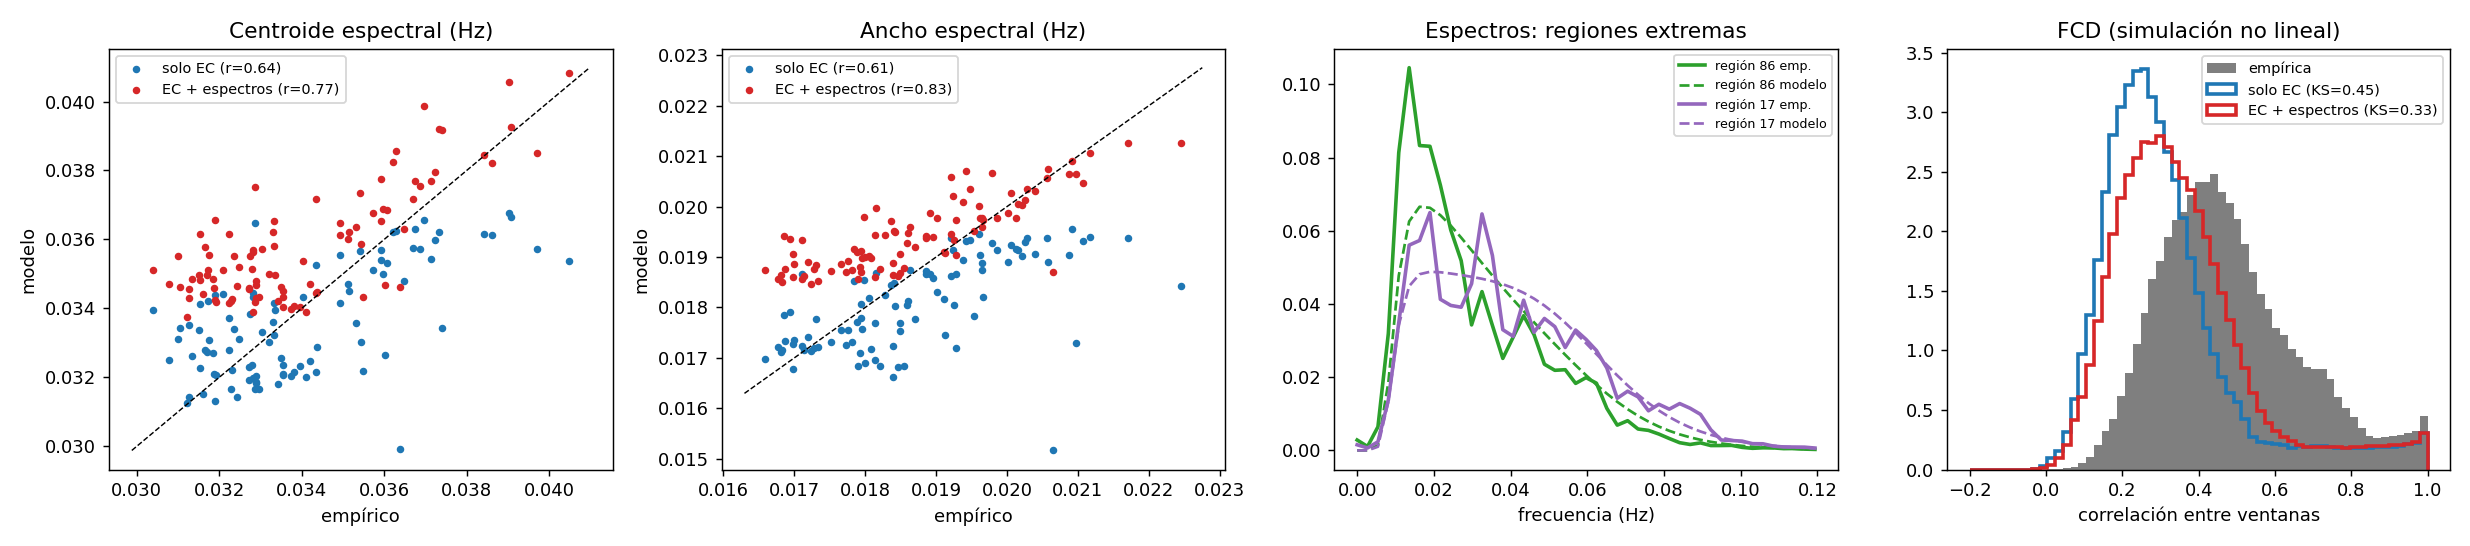

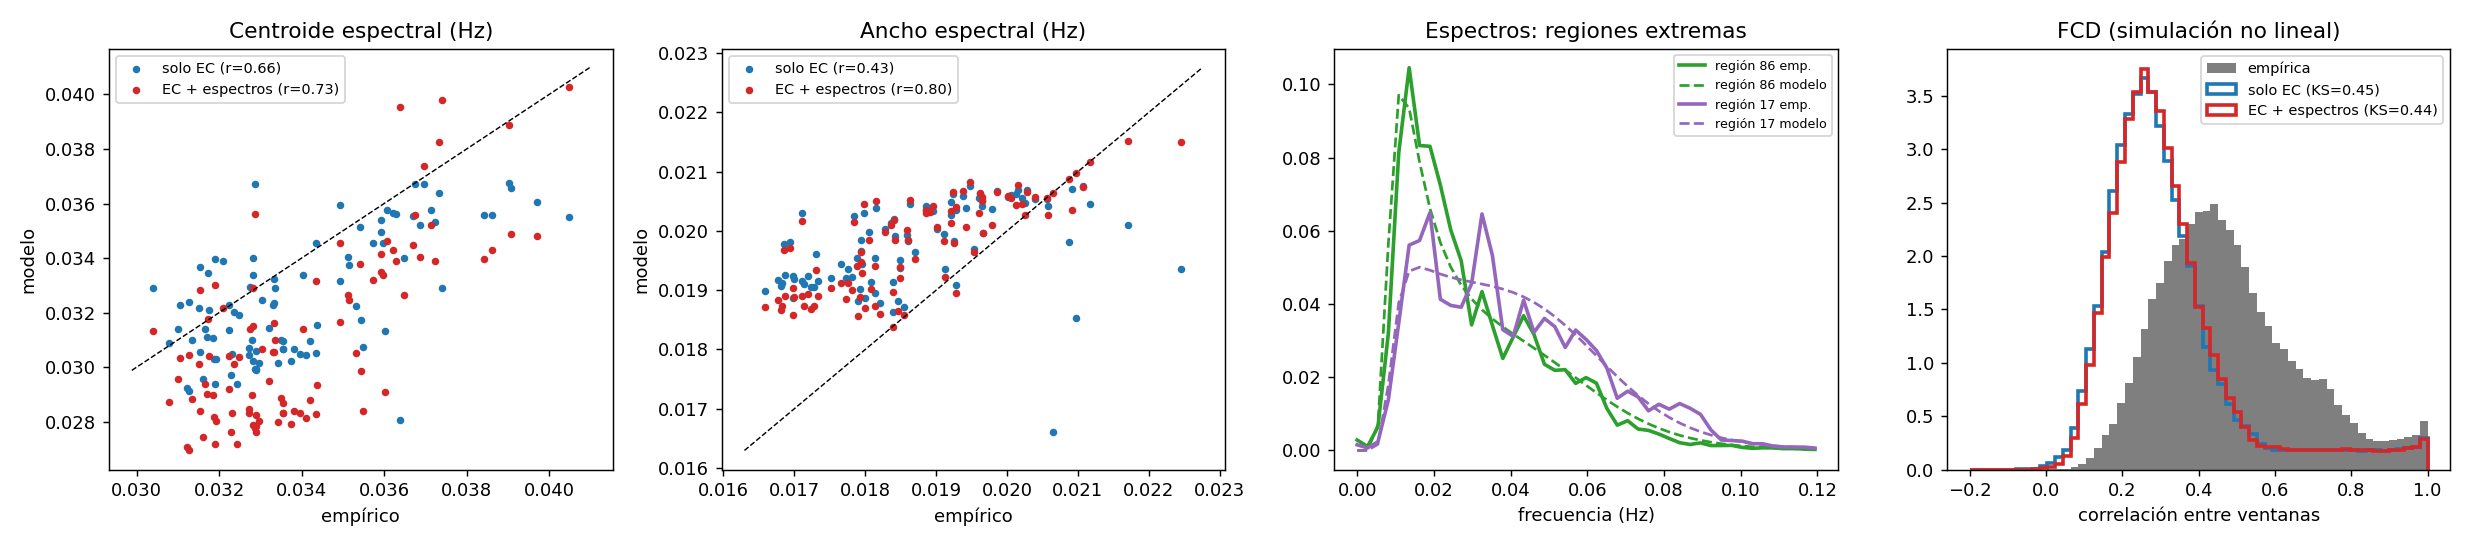

In [2]:
display(Image(str(ROOT/'figures'/'fase4_espectros_fcd.png')))
display(Image(str(ROOT/'figures'/'fase4_espectros_fcd_mou.png')))

## Lectura

**1. Los espectros regionales mejoran, pero la FCD sigue sin cerrarse.**
- En sujetos de prueba, el centroide sube de 0.56 a 0.62–0.64 y el ancho de 0.54 a 0.63–0.69, contra un techo de 0.76.
- La FCD mejora con el modelo de Hopf (KS de 0.45 a 0.33), pero queda lejos del 0.09 del control empírico.
- Entre modelos, la FCD sigue a la *forma completa* del espectro (distancia TV), no solo a sus dos primeros momentos. Hopf tiene un parámetro más por región, empata mejor la forma (TV 0.14 frente a 0.20) y obtiene mejor FCD (0.33 frente a 0.44).

**2. La oscilación local no está respaldada por estos datos.**
- El modelo OU sin oscilación iguala o supera a Hopf en FC (0.77 frente a 0.73 en prueba), en momentos espectrales y en el nivel de FC (0.374 frente a 0.373 empírico).
- Para ajustar los espectros, Hopf manda **89 de 94 frecuencias a los límites**, fuera de la banda del BOLD. Es decir, "apaga" su oscilación. Los espectros del BOLD filtrado son anchos y no muestran picos.

**3. Advertencia central para el programa: $a_j$ y $\delta$ no están identificados.**
- En ambos modelos, entre 73 y 80 de 94 $a_j$ terminan en los límites. La mayoría se va a $|a_j|=10^{-3}$, nodos localmente en la bifurcación, y algunas a $|a_j|=1$.
- Con acoplamiento difusivo, el amortiguamiento lo pone la red y no el nodo. Aun con $a_j\approx0$, la distancia global a la criticalidad sale positiva.
- Pero **$\delta$ cambia mucho según el modelo**: 0.07 con $a$ homogéneo (Fase 2), 0.146 con Hopf más espectros y 0.029 con OU más espectros. Son tiempos de relajación de 7 a 34 s.

**Conclusión:** con 7 sujetos, una sola sesión y BOLD filtrado, **la distancia a la criticalidad no es un parámetro que se pueda estimar de forma robusta**. Depende de supuestos del modelo que los datos no distinguen. Antes de comparar $\delta$ entre grupos (autismo, envejecimiento) hay que:
- usar más datos (más sujetos y sesiones; el techo de ruido de 0.80 es el límite actual);
- buscar observables que identifiquen la cercanía a la bifurcación sin depender del modelo, como las firmas de no linealidad o de irreversibilidad que un proceso lineal no puede producir.